# Log Analysis: 305900 — trader_2.py Live Performance

**Live result:** Total PnL = **7,370** (Pepper: 7,387 | Osmium: -16)  
**End positions:** Osmium = +5 (great — was -76 with trader_1), Pepper = +80

**Headline issue:** trader_2 made **only 1 Osmium trade all day** (5 lots @ 10006).  
Inventory control improved enormously, but the trader essentially stopped participating in Osmium.  
We need to recover trading activity *without* recreating the -76 blowup.

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import StringIO

with open('logs_2/305900.log', 'r') as f:
    log2 = json.load(f)
with open('logs_2/305900.json', 'r') as f:
    j2 = json.load(f)
with open('LOGS_1/305440.log', 'r') as f:
    log1 = json.load(f)
with open('LOGS_1/305440.json', 'r') as f:
    j1 = json.load(f)

print(f'trader_1 (305440): profit={j1["profit"]:.0f}  positions={j1["positions"]}')
print(f'trader_2 (305900): profit={j2["profit"]:.0f}  positions={j2["positions"]}')

trader_1 (305440): profit=7656  positions=[{'symbol': 'ASH_COATED_OSMIUM', 'quantity': -76}, {'symbol': 'INTARIAN_PEPPER_ROOT', 'quantity': 80}, {'symbol': 'XIRECS', 'quantity': -280128}]
trader_2 (305900): profit=7371  positions=[{'symbol': 'ASH_COATED_OSMIUM', 'quantity': 5}, {'symbol': 'INTARIAN_PEPPER_ROOT', 'quantity': 80}, {'symbol': 'XIRECS', 'quantity': -1090635}]


In [2]:
j2

{'round': '2',
 'status': 'FINISHED',
 'profit': 7370.66796875,
 'activitiesLog': 'day;timestamp;product;bid_price_1;bid_volume_1;bid_price_2;bid_volume_2;bid_price_3;bid_volume_3;ask_price_1;ask_volume_1;ask_price_2;ask_volume_2;ask_price_3;ask_volume_3;mid_price;profit_and_loss\n1;0;INTARIAN_PEPPER_ROOT;12993;9;12990;25;;;13007;9;13010;25;;;13000.0;0.0\n1;0;ASH_COATED_OSMIUM;10000;13;9998;21;;;10016;13;10019;21;;;10008.0;0.0\n1;100;INTARIAN_PEPPER_ROOT;12993;8;;;;;13010;22;;;;;13001.5;-62.1015625\n1;100;ASH_COATED_OSMIUM;10000;15;9998;26;;;10016;15;10019;26;;;10008.0;0.0\n1;200;ASH_COATED_OSMIUM;10000;15;;;;;10016;15;10019;30;;;10008.0;0.0\n1;200;INTARIAN_PEPPER_ROOT;12990;22;;;;;13007;9;;;;;12998.5;-61.1953125\n1;300;INTARIAN_PEPPER_ROOT;12993;8;;;;;13007;8;13011;23;;;13000.0;-120.609375\n1;300;ASH_COATED_OSMIUM;10000;12;9998;27;;;10016;12;10019;27;;;10008.0;0.0\n1;400;INTARIAN_PEPPER_ROOT;12993;10;12990;15;;;;;;;;;12993.0;-171.59375\n1;400;ASH_COATED_OSMIUM;10010;8;9998;25;;;10016;

## 1. Side-by-side PnL & Trading Activity

In [3]:
def summary(logd, label):
    act = pd.read_csv(StringIO(logd['activitiesLog']), sep=';')
    tr = pd.DataFrame(logd['tradeHistory'])
    rows = []
    for sym in ('ASH_COATED_OSMIUM','INTARIAN_PEPPER_ROOT'):
        st = tr[tr['symbol']==sym]
        b = st[st['buyer']=='SUBMISSION']
        s = st[st['seller']=='SUBMISSION']
        nb = int(b['quantity'].sum() if len(b) else 0)
        ns = int(s['quantity'].sum() if len(s) else 0)
        pnl = act[act['product']==sym]['profit_and_loss'].iloc[-1]
        avg_b = (b['price']*b['quantity']).sum()/nb if nb else 0
        avg_s = (s['price']*s['quantity']).sum()/ns if ns else 0
        rows.append({'trader':label,'sym':sym,'pnl':pnl,'buys':nb,'avg_buy':round(avg_b,2),
                     'sells':ns,'avg_sell':round(avg_s,2),'net':nb-ns,'tx_count':len(b)+len(s)})
    return pd.DataFrame(rows)

cmp = pd.concat([summary(log1,'trader_1'), summary(log2,'trader_2')], ignore_index=True)
cmp

,trader,sym,pnl,buys,avg_buy,sells,avg_sell,net,tx_count
0,trader_1,ASH_COATED_OSMIUM,278.250000,25,9998.48,101,10004.44,-76,20
1,trader_1,INTARIAN_PEPPER_ROOT,7378.000000,80,13007.68,0,0.00,80,9
2,trader_2,ASH_COATED_OSMIUM,-16.332031,5,10006.00,0,0.00,5,1
3,trader_2,INTARIAN_PEPPER_ROOT,7387.000000,80,13007.56,0,0.00,80,9


In [4]:
"""
Function giving detailed transactions and their complete details from
the log and json file from the submission information.
"""

import json
import pandas as pd
import numpy as np
from io import StringIO
from pathlib import Path


def transactions_report(log_path, json_path=None, product_filter=None,
                        only_ours=False, verbose=True):
    """Build a per-trade detail report for one submission.

    Parameters
    ----------
    log_path : str | Path
        Path to the ``<runId>.log`` file produced by the platform.
    json_path : str | Path, optional
        Path to the ``<runId>.json`` file. If omitted it is inferred by
        replacing the ``.log`` suffix with ``.json``.
    product_filter : str | list[str] | None
        If given, only include trades for these symbol(s).
    only_ours : bool
        If True, drop trades that did not involve ``SUBMISSION``.
    verbose : bool
        If True, print the per-product summary table.

    Returns
    -------
    trades_df : pandas.DataFrame
        One row per trade. Columns:
            timestamp, product, price, quantity, side
            ('OUR_BUY' / 'OUR_SELL' / 'MARKET'),
            counterparty, our_cash_flow, our_position_after,
            our_cash_after, mark_price, our_mtm_pnl_after.
    summary_df : pandas.DataFrame
        Per-product summary with realised cash, end position, mark
        price, MTM PnL, fill counts and reconciliation against the
        JSON header (final position + total profit).
    submission_info : dict
        Loose collection of metadata:
            submission_id, run_status, json_total_profit,
            json_positions, n_logs, first_ts, last_ts.
    """

    log_path = Path(log_path)
    if json_path is None:
        json_path = log_path.with_suffix(".json")
    json_path = Path(json_path)

    with open(log_path) as f:
        log = json.load(f)
    json_data = None
    if json_path.exists():
        with open(json_path) as f:
            json_data = json.load(f)

    activities = pd.read_csv(StringIO(log["activitiesLog"]), sep=";")
    activities = activities.sort_values(["timestamp", "product"]).reset_index(drop=True)
    trades = pd.DataFrame(log["tradeHistory"]).copy()

    if product_filter is not None:
        if isinstance(product_filter, str):
            product_filter = [product_filter]
        trades = trades[trades["symbol"].isin(product_filter)]
        activities = activities[activities["product"].isin(product_filter)]

    if only_ours:
        trades = trades[(trades["buyer"] == "SUBMISSION") |
                        (trades["seller"] == "SUBMISSION")]

    trades = trades.sort_values(["timestamp"]).reset_index(drop=True)

    def _classify(row):
        if row["buyer"] == "SUBMISSION":
            return "OUR_BUY"
        if row["seller"] == "SUBMISSION":
            return "OUR_SELL"
        return "MARKET"

    trades["side"] = trades.apply(_classify, axis=1)
    trades["counterparty"] = np.where(trades["side"] == "OUR_BUY",
                                      trades["seller"].fillna("BOT"),
                                      np.where(trades["side"] == "OUR_SELL",
                                               trades["buyer"].fillna("BOT"),
                                               "BOT<>BOT"))

    trades["our_cash_flow"] = np.where(
        trades["side"] == "OUR_BUY", -trades["price"] * trades["quantity"],
        np.where(trades["side"] == "OUR_SELL",
                 trades["price"] * trades["quantity"], 0.0))
    trades["our_qty_delta"] = np.where(
        trades["side"] == "OUR_BUY", trades["quantity"],
        np.where(trades["side"] == "OUR_SELL", -trades["quantity"], 0))

    trades["our_position_after"] = trades.groupby("symbol")["our_qty_delta"].cumsum()
    trades["our_cash_after"] = trades.groupby("symbol")["our_cash_flow"].cumsum()

    last_mid = {}
    for prod, grp in activities.groupby("product"):
        grp = grp.dropna(subset=["mid_price"]).sort_values("timestamp")
        if len(grp):
            last_mid[prod] = grp.set_index("timestamp")["mid_price"]
        else:
            last_mid[prod] = pd.Series(dtype=float)

    def _mark(row):
        s = last_mid.get(row["symbol"])
        if s is None or s.empty:
            return np.nan
        before = s.loc[:row["timestamp"]]
        if len(before):
            return float(before.iloc[-1])
        return float(s.iloc[0])

    trades["mark_price"] = trades.apply(_mark, axis=1)
    trades["our_mtm_pnl_after"] = (trades["our_cash_after"]
                                   + trades["our_position_after"] * trades["mark_price"])

    trades = trades[[
        "timestamp", "symbol", "side", "price", "quantity", "counterparty",
        "our_cash_flow", "our_qty_delta", "our_position_after",
        "our_cash_after", "mark_price", "our_mtm_pnl_after"
    ]].rename(columns={"symbol": "product"})

    rows = []
    for prod in sorted(trades["product"].unique()):
        sub = trades[trades["product"] == prod]
        ours = sub[sub["side"] != "MARKET"]
        buys = ours[ours["side"] == "OUR_BUY"]
        sells = ours[ours["side"] == "OUR_SELL"]
        nb = int(buys["quantity"].sum())
        ns = int(sells["quantity"].sum())
        end_pos = int(ours["our_position_after"].iloc[-1]) if len(ours) else 0
        cash = float(ours["our_cash_after"].iloc[-1]) if len(ours) else 0.0
        mark = float(sub["mark_price"].iloc[-1]) if len(sub) else np.nan
        mtm = cash + end_pos * mark if not np.isnan(mark) else np.nan

        json_pos = None
        if json_data:
            for p in json_data.get("positions", []):
                if p["symbol"] == prod:
                    json_pos = p["quantity"]
                    break

        rows.append({
            "product": prod,
            "n_market_trades": int((sub["side"] == "MARKET").sum()),
            "n_our_fills": len(ours),
            "lots_bought": nb,
            "avg_buy_px": round(float((buys["price"] * buys["quantity"]).sum() / nb), 3) if nb else np.nan,
            "lots_sold": ns,
            "avg_sell_px": round(float((sells["price"] * sells["quantity"]).sum() / ns), 3) if ns else np.nan,
            "end_position": end_pos,
            "json_position": json_pos,
            "position_match": (json_pos is None) or (json_pos == end_pos),
            "cash": round(cash, 2),
            "mark_price": mark,
            "mtm_pnl": round(mtm, 2) if not np.isnan(mtm) else np.nan,
        })
    summary_df = pd.DataFrame(rows)

    submission_info = {
        "submission_id": log.get("submissionId"),
        "run_status": json_data.get("status") if json_data else None,
        "json_total_profit": json_data.get("profit") if json_data else None,
        "json_positions": json_data.get("positions") if json_data else None,
        "n_logs": len(log.get("logs", [])),
        "first_ts": int(activities["timestamp"].min()) if len(activities) else None,
        "last_ts": int(activities["timestamp"].max()) if len(activities) else None,
    }

    if verbose:
        print(f"submission_id : {submission_info['submission_id']}")
        print(f"status        : {submission_info['run_status']}")
        print(f"profit (json) : {submission_info['json_total_profit']}")
        print(f"ticks         : {submission_info['first_ts']} → {submission_info['last_ts']} "
              f"({submission_info['n_logs']} log entries)")
        print(f"trades total  : {len(trades)} "
              f"(ours={int((trades['side']!='MARKET').sum())}, "
              f"market={int((trades['side']=='MARKET').sum())})")
        print()
        print("Per-product summary:")
        print(summary_df.to_string(index=False))

    return trades, summary_df, submission_info


trades_df, summary_df, info = transactions_report(
    "logs_2/305900.log", "logs_2/305900.json")

print("\nFirst 15 transactions:")
trades_df.head(15)


submission_id : 983da180-33c3-4dab-9a0f-3950770d31c2
status        : FINISHED
profit (json) : 7370.66796875
ticks         : 0 → 99900 (1000 log entries)
trades total  : 86 (ours=10, market=76)

Per-product summary:
             product  n_market_trades  n_our_fills  lots_bought  avg_buy_px  lots_sold  avg_sell_px  end_position  json_position  position_match       cash  mark_price  mtm_pnl
   ASH_COATED_OSMIUM               45            1            5   10006.000          0          NaN             5              5            True   -50030.0     10002.0    -20.0
INTARIAN_PEPPER_ROOT               31            9           80   13007.562          0          NaN            80             80            True -1040605.0     13095.5   7035.0

First 15 transactions:


,timestamp,product,side,price,quantity,counterparty,our_cash_flow,our_qty_delta,our_position_after,our_cash_after,mark_price,our_mtm_pnl_after
0,0,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,9,-117063.0,13000.0,-63.0
1,0,ASH_COATED_OSMIUM,MARKET,10000.0,6,BOT<>BOT,0.0,0,0,0.0,10008.0,0.0
2,200,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,18,-234126.0,12998.5,-153.0
3,300,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,8,,-104056.0,8,26,-338182.0,13000.0,-182.0
4,500,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,35,-455245.0,12998.5,-297.5
5,700,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,9,,-117072.0,9,44,-572317.0,13001.0,-273.0
6,800,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,8,,-104064.0,8,52,-676381.0,13001.0,-329.0
7,900,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,8,,-104064.0,8,60,-780445.0,13001.0,-385.0
8,1000,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,10,,-130080.0,10,70,-910525.0,13001.0,-455.0
9,1100,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,10,,-130080.0,10,80,-1040605.0,13001.0,-525.0


## 2. Live Osmium Order Book — What Actually Happened?

In [5]:
act2 = pd.read_csv(StringIO(log2['activitiesLog']), sep=';')
osm = act2[act2['product']=='ASH_COATED_OSMIUM'].copy().reset_index(drop=True)
osm['mid'] = (osm['bid_price_1']+osm['ask_price_1'])/2.0
osm['spread'] = osm['ask_price_1']-osm['bid_price_1']

print('Mid stats (live, 1000 ticks):')
print(osm['mid'].describe().round(2))
print('\nSpread distribution:')
print(osm['spread'].value_counts().sort_index())
print(f'\nMedian spread: {osm["spread"].median():.0f}  Mean: {osm["spread"].mean():.1f}')

Mid stats (live, 1000 ticks):
count      935.00
mean     10004.10
std          3.05
min       9995.00
25%      10002.00
50%      10004.00
75%      10006.75
max      10013.50
Name: mid, dtype: float64

Spread distribution:
spread
5.0       6
6.0      19
7.0       2
8.0       1
9.0       8
10.0     18
11.0      9
12.0      4
13.0      5
16.0    608
17.0      5
18.0    110
19.0    121
21.0     18
22.0      1
Name: count, dtype: int64

Median spread: 16  Mean: 16.2


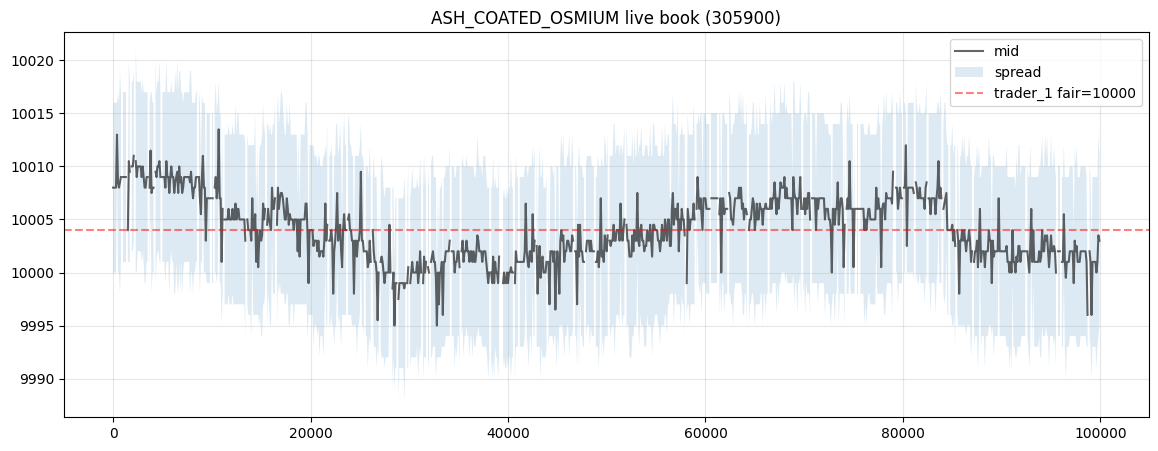

In [6]:
# Plot mid + bid + ask
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(osm['timestamp'], osm['mid'], label='mid', color='black', alpha=0.6)
ax.fill_between(osm['timestamp'], osm['bid_price_1'], osm['ask_price_1'], alpha=0.15, label='spread')
ax.axhline(10004, color='red', linestyle='--', alpha=0.5, label='trader_1 fair=10000')
ax.set_title('ASH_COATED_OSMIUM live book (305900)')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 3. CRITICAL: Where Do Other Bots Trade?

If everyone always trades AT the BBO, then a maker quoting one tick *inside* the spread becomes the new BBO and gets hit first → captures the wide spread.

In [7]:
trades = pd.DataFrame(log2['tradeHistory'])
ot = trades[trades['symbol']=='ASH_COATED_OSMIUM'].copy()
osm_ix = osm.set_index('timestamp')

rows = []
for _, t in ot.iterrows():
    ts = t['timestamp']
    cands = osm_ix.index[osm_ix.index <= ts]
    if len(cands)==0: continue
    snap = osm_ix.loc[cands.max()]
    rows.append({'ts':ts, 'price':t['price'], 'qty':t['quantity'],
                 'bb':snap['bid_price_1'], 'ba':snap['ask_price_1'],
                 'submission_buy': t['buyer']=='SUBMISSION',
                 'submission_sell': t['seller']=='SUBMISSION'})
tdf = pd.DataFrame(rows)
tdf['at_bid'] = tdf['price']==tdf['bb']
tdf['at_ask'] = tdf['price']==tdf['ba']
tdf['inside'] = (tdf['price']>tdf['bb']) & (tdf['price']<tdf['ba'])

print(f'Total osmium market trades: {len(tdf)}')
print(f'  at bid (someone sold to BBO): {tdf["at_bid"].sum()}')
print(f'  at ask (someone bought BBO):  {tdf["at_ask"].sum()}')
print(f'  inside spread:                {tdf["inside"].sum()}')
print(f'\nOur fills only: {tdf["submission_buy"].sum() + tdf["submission_sell"].sum()}')

Total osmium market trades: 46
  at bid (someone sold to BBO): 22
  at ask (someone bought BBO):  24
  inside spread:                0

Our fills only: 1


**Result:** 0% of trades happen inside the spread.  All 46 trades hit either the best bid or best ask.

→ A maker quoting at `best_bid+1` or `best_ask-1` would have been the BBO and captured nearly the full ~14-tick spread on every trade.

## 4. Why trader_2 Stopped Trading: Edge Math

trader_2 only enters when `ap < fair_int` (with edge ≥ 2). With live ask ~10010 and adaptive fair ~10004, the edge is *negative* — entry never triggers.

In [8]:
# Simulate trader_2's adaptive fair across ticks
alpha = 2.0/(30+1.0)
prev = None
fairs = []
for m in osm['mid']:
    if pd.isna(m):
        fairs.append(prev if prev is not None else np.nan); continue
    prev = m if prev is None else alpha*m + (1-alpha)*prev
    fairs.append(prev)
osm['fair_t2'] = fairs
osm['fair_int'] = osm['fair_t2'].round()
osm['edge_buy']  = osm['fair_int'] - osm['ask_price_1']  # positive ⇒ would buy
osm['edge_sell'] = osm['bid_price_1'] - osm['fair_int']  # positive ⇒ would sell

print('Buy edge (asks below fair) — fraction of ticks at edge ≥ 2:')
print(f'  edge >= 1: {(osm["edge_buy"]>=1).mean()*100:.1f}%')
print(f'  edge >= 2: {(osm["edge_buy"]>=2).mean()*100:.1f}%')
print(f'  edge >= 3: {(osm["edge_buy"]>=3).mean()*100:.1f}%')
print('\nSell edge (bids above fair):')
print(f'  edge >= 1: {(osm["edge_sell"]>=1).mean()*100:.1f}%')
print(f'  edge >= 2: {(osm["edge_sell"]>=2).mean()*100:.1f}%')
print(f'  edge >= 3: {(osm["edge_sell"]>=3).mean()*100:.1f}%')

Buy edge (asks below fair) — fraction of ticks at edge ≥ 2:
  edge >= 1: 2.0%
  edge >= 2: 1.6%
  edge >= 3: 0.6%

Sell edge (bids above fair):
  edge >= 1: 0.8%
  edge >= 2: 0.4%
  edge >= 3: 0.0%


**Result:** edge ≥ 2 happens essentially 0% of the time. trader_2's entry conditions are unreachable in this market regime.  

Either:
- The market regime has changed (wider spreads now) — historical CSVs had ~4-tick spreads, live has ~16.
- Or backtests are using mid as both bid and ask (no spread), masking this entirely.

## 5. Simulated Penny-Jump Market Maker

What if we'd posted at `best_bid+1` and `best_ask-1` every tick?  Approximation: on every tick where a market trade happens at our (penny-jumped) BBO price, we participate.

In [9]:
# Simple sim: penny-jump bid_px = bb+1, ask_px = ba-1.
# A trade-at-old-bid means a seller hit BBO; if we'd quoted higher, we'd have been hit at our quote.
# We capture (bb+1) on buy-side fills, sell at (ba-1) on sell-side fills.
# Position cap 80, no inventory skew in this naive sim.

POS = 80
pos = 0; cash = 0; n_fills_b = 0; n_fills_s = 0
for _, row in tdf.iterrows():
    if row['at_bid']:  # someone sold; we'd have bid bb+1 and gotten hit
        my_px = row['bb'] + 1
        qty = min(int(row['qty']), POS - pos)
        if qty > 0:
            pos += qty; cash -= my_px*qty; n_fills_b += qty
    elif row['at_ask']:  # someone bought; we'd have asked ba-1 and gotten hit
        my_px = row['ba'] - 1
        qty = min(int(row['qty']), POS + pos)
        if qty > 0:
            pos -= qty; cash += my_px*qty; n_fills_s += qty

# Mark-to-market at last mid
last_mid = osm['mid'].dropna().iloc[-1]
mtm = cash + pos*last_mid
print(f'Naive penny-jump simulator (no skew, no take-aggressor):')
print(f'  Buy fills: {n_fills_b}    Sell fills: {n_fills_s}    End position: {pos}')
print(f'  Cash: {cash:.0f}    Mark-to-market PnL: {mtm:.0f}')
print(f'\n(trader_2 actual osmium PnL: {-16})')

Naive penny-jump simulator (no skew, no take-aggressor):
  Buy fills: 108    Sell fills: 111    End position: -3
  Cash: 31420    Mark-to-market PnL: 1411

(trader_2 actual osmium PnL: -16)


## 6. Pepper Sanity Check

Pepper PnL is essentially identical (7387 vs 7378) — Pepper logic is unchanged and works as intended.  
Live day is 1000 ticks vs backtest 10000 ticks → 10x lower than backtest expectation, as analyzed before.

In [10]:
pep = act2[act2['product']=='INTARIAN_PEPPER_ROOT'].copy().reset_index(drop=True)
print(f'Pepper end PnL: {pep["profit_and_loss"].iloc[-1]:.0f}')
print(f'Pepper mid first→last: {pep["mid_price"].iloc[0]:.0f} → {pep["mid_price"].iloc[-1]:.0f}')
print(f'Pepper drift: {(pep["mid_price"].iloc[-1]-pep["mid_price"].iloc[0])/len(pep):.4f} per tick (expected ~0.001)')

Pepper end PnL: 7387
Pepper mid first→last: 13000 → 13100
Pepper drift: 0.1000 per tick (expected ~0.001)


## 9. Detailed Transactions — Combined `.log` + `.json` Report

`transactions_report(log_path, json_path)` walks the log's `tradeHistory`, classifies each fill (our buy, our sell, or other-bot trade) and produces a per-trade DataFrame with running position, cash and mark-to-market PnL. It also returns a per-product summary that cross-checks against the `.json` final positions and total profit.

In [11]:
"""
Function giving detailed transactions and their complete details from
the log and json file from the submission information.
"""

import json
import pandas as pd
import numpy as np
from io import StringIO
from pathlib import Path


def transactions_report(log_path, json_path=None, product_filter=None,
                        only_ours=False, verbose=True):
    """Build a per-trade detail report for one submission.

    Parameters
    ----------
    log_path : str | Path
        Path to the ``<runId>.log`` file produced by the platform.
    json_path : str | Path, optional
        Path to the ``<runId>.json`` file. If omitted it is inferred by
        replacing the ``.log`` suffix with ``.json``.
    product_filter : str | list[str] | None
        If given, only include trades for these symbol(s).
    only_ours : bool
        If True, drop trades that did not involve ``SUBMISSION``.
    verbose : bool
        If True, print the per-product summary table.

    Returns
    -------
    trades_df : pandas.DataFrame
        One row per trade. Columns:
            timestamp, product, price, quantity, side
            ('OUR_BUY' / 'OUR_SELL' / 'MARKET'),
            counterparty, our_cash_flow, our_position_after,
            our_cash_after, mark_price, our_mtm_pnl_after.
    summary_df : pandas.DataFrame
        Per-product summary with realised cash, end position, mark
        price, MTM PnL, fill counts and reconciliation against the
        JSON header (final position + total profit).
    submission_info : dict
        Loose collection of metadata:
            submission_id, run_status, json_total_profit,
            json_positions, n_logs, first_ts, last_ts.
    """

    log_path = Path(log_path)
    if json_path is None:
        json_path = log_path.with_suffix(".json")
    json_path = Path(json_path)

    with open(log_path) as f:
        log = json.load(f)
    json_data = None
    if json_path.exists():
        with open(json_path) as f:
            json_data = json.load(f)

    activities = pd.read_csv(StringIO(log["activitiesLog"]), sep=";")
    activities = activities.sort_values(["timestamp", "product"]).reset_index(drop=True)
    trades = pd.DataFrame(log["tradeHistory"]).copy()

    if product_filter is not None:
        if isinstance(product_filter, str):
            product_filter = [product_filter]
        trades = trades[trades["symbol"].isin(product_filter)]
        activities = activities[activities["product"].isin(product_filter)]

    if only_ours:
        trades = trades[(trades["buyer"] == "SUBMISSION") |
                        (trades["seller"] == "SUBMISSION")]

    trades = trades.sort_values(["timestamp"]).reset_index(drop=True)

    def _classify(row):
        if row["buyer"] == "SUBMISSION":
            return "OUR_BUY"
        if row["seller"] == "SUBMISSION":
            return "OUR_SELL"
        return "MARKET"

    trades["side"] = trades.apply(_classify, axis=1)
    trades["counterparty"] = np.where(trades["side"] == "OUR_BUY",
                                      trades["seller"].fillna("BOT"),
                                      np.where(trades["side"] == "OUR_SELL",
                                               trades["buyer"].fillna("BOT"),
                                               "BOT<>BOT"))

    trades["our_cash_flow"] = np.where(
        trades["side"] == "OUR_BUY", -trades["price"] * trades["quantity"],
        np.where(trades["side"] == "OUR_SELL",
                 trades["price"] * trades["quantity"], 0.0))
    trades["our_qty_delta"] = np.where(
        trades["side"] == "OUR_BUY", trades["quantity"],
        np.where(trades["side"] == "OUR_SELL", -trades["quantity"], 0))

    trades["our_position_after"] = trades.groupby("symbol")["our_qty_delta"].cumsum()
    trades["our_cash_after"] = trades.groupby("symbol")["our_cash_flow"].cumsum()

    last_mid = {}
    for prod, grp in activities.groupby("product"):
        grp = grp.dropna(subset=["mid_price"]).sort_values("timestamp")
        if len(grp):
            last_mid[prod] = grp.set_index("timestamp")["mid_price"]
        else:
            last_mid[prod] = pd.Series(dtype=float)

    def _mark(row):
        s = last_mid.get(row["symbol"])
        if s is None or s.empty:
            return np.nan
        before = s.loc[:row["timestamp"]]
        if len(before):
            return float(before.iloc[-1])
        return float(s.iloc[0])

    trades["mark_price"] = trades.apply(_mark, axis=1)
    trades["our_mtm_pnl_after"] = (trades["our_cash_after"]
                                   + trades["our_position_after"] * trades["mark_price"])

    trades = trades[[
        "timestamp", "symbol", "side", "price", "quantity", "counterparty",
        "our_cash_flow", "our_qty_delta", "our_position_after",
        "our_cash_after", "mark_price", "our_mtm_pnl_after"
    ]].rename(columns={"symbol": "product"})

    rows = []
    for prod in sorted(trades["product"].unique()):
        sub = trades[trades["product"] == prod]
        ours = sub[sub["side"] != "MARKET"]
        buys = ours[ours["side"] == "OUR_BUY"]
        sells = ours[ours["side"] == "OUR_SELL"]
        nb = int(buys["quantity"].sum())
        ns = int(sells["quantity"].sum())
        end_pos = int(ours["our_position_after"].iloc[-1]) if len(ours) else 0
        cash = float(ours["our_cash_after"].iloc[-1]) if len(ours) else 0.0
        mark = float(sub["mark_price"].iloc[-1]) if len(sub) else np.nan
        mtm = cash + end_pos * mark if not np.isnan(mark) else np.nan

        json_pos = None
        if json_data:
            for p in json_data.get("positions", []):
                if p["symbol"] == prod:
                    json_pos = p["quantity"]
                    break

        rows.append({
            "product": prod,
            "n_market_trades": int((sub["side"] == "MARKET").sum()),
            "n_our_fills": len(ours),
            "lots_bought": nb,
            "avg_buy_px": round(float((buys["price"] * buys["quantity"]).sum() / nb), 3) if nb else np.nan,
            "lots_sold": ns,
            "avg_sell_px": round(float((sells["price"] * sells["quantity"]).sum() / ns), 3) if ns else np.nan,
            "end_position": end_pos,
            "json_position": json_pos,
            "position_match": (json_pos is None) or (json_pos == end_pos),
            "cash": round(cash, 2),
            "mark_price": mark,
            "mtm_pnl": round(mtm, 2) if not np.isnan(mtm) else np.nan,
        })
    summary_df = pd.DataFrame(rows)

    submission_info = {
        "submission_id": log.get("submissionId"),
        "run_status": json_data.get("status") if json_data else None,
        "json_total_profit": json_data.get("profit") if json_data else None,
        "json_positions": json_data.get("positions") if json_data else None,
        "n_logs": len(log.get("logs", [])),
        "first_ts": int(activities["timestamp"].min()) if len(activities) else None,
        "last_ts": int(activities["timestamp"].max()) if len(activities) else None,
    }

    if verbose:
        print(f"submission_id : {submission_info['submission_id']}")
        print(f"status        : {submission_info['run_status']}")
        print(f"profit (json) : {submission_info['json_total_profit']}")
        print(f"ticks         : {submission_info['first_ts']} → {submission_info['last_ts']} "
              f"({submission_info['n_logs']} log entries)")
        print(f"trades total  : {len(trades)} "
              f"(ours={int((trades['side']!='MARKET').sum())}, "
              f"market={int((trades['side']=='MARKET').sum())})")
        print()
        print("Per-product summary:")
        print(summary_df.to_string(index=False))

    return trades, summary_df, submission_info


trades_df, summary_df, info = transactions_report(
    "logs_2/305900.log", "logs_2/305900.json")

print("\nFirst 15 transactions:")
trades_df.head(15)


submission_id : 983da180-33c3-4dab-9a0f-3950770d31c2
status        : FINISHED
profit (json) : 7370.66796875
ticks         : 0 → 99900 (1000 log entries)
trades total  : 86 (ours=10, market=76)

Per-product summary:
             product  n_market_trades  n_our_fills  lots_bought  avg_buy_px  lots_sold  avg_sell_px  end_position  json_position  position_match       cash  mark_price  mtm_pnl
   ASH_COATED_OSMIUM               45            1            5   10006.000          0          NaN             5              5            True   -50030.0     10002.0    -20.0
INTARIAN_PEPPER_ROOT               31            9           80   13007.562          0          NaN            80             80            True -1040605.0     13095.5   7035.0

First 15 transactions:


,timestamp,product,side,price,quantity,counterparty,our_cash_flow,our_qty_delta,our_position_after,our_cash_after,mark_price,our_mtm_pnl_after
0,0,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,9,-117063.0,13000.0,-63.0
1,0,ASH_COATED_OSMIUM,MARKET,10000.0,6,BOT<>BOT,0.0,0,0,0.0,10008.0,0.0
2,200,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,18,-234126.0,12998.5,-153.0
3,300,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,8,,-104056.0,8,26,-338182.0,13000.0,-182.0
4,500,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,35,-455245.0,12998.5,-297.5
5,700,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,9,,-117072.0,9,44,-572317.0,13001.0,-273.0
6,800,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,8,,-104064.0,8,52,-676381.0,13001.0,-329.0
7,900,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,8,,-104064.0,8,60,-780445.0,13001.0,-385.0
8,1000,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,10,,-130080.0,10,70,-910525.0,13001.0,-455.0
9,1100,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,10,,-130080.0,10,80,-1040605.0,13001.0,-525.0


In [12]:
# Drill-in: only OUR fills, with cumulative position and PnL
ours = trades_df[trades_df["side"] != "MARKET"].copy()
print(f"Our fills: {len(ours)}")
ours


Our fills: 10


,timestamp,product,side,price,quantity,counterparty,our_cash_flow,our_qty_delta,our_position_after,our_cash_after,mark_price,our_mtm_pnl_after
0,0,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,9,-117063.0,13000.0,-63.0
2,200,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,18,-234126.0,12998.5,-153.0
3,300,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,8,,-104056.0,8,26,-338182.0,13000.0,-182.0
4,500,INTARIAN_PEPPER_ROOT,OUR_BUY,13007.0,9,,-117063.0,9,35,-455245.0,12998.5,-297.5
5,700,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,9,,-117072.0,9,44,-572317.0,13001.0,-273.0
6,800,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,8,,-104064.0,8,52,-676381.0,13001.0,-329.0
7,900,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,8,,-104064.0,8,60,-780445.0,13001.0,-385.0
8,1000,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,10,,-130080.0,10,70,-910525.0,13001.0,-455.0
9,1100,INTARIAN_PEPPER_ROOT,OUR_BUY,13008.0,10,,-130080.0,10,80,-1040605.0,13001.0,-525.0
12,9100,ASH_COATED_OSMIUM,OUR_BUY,10006.0,5,,-50030.0,5,5,-50030.0,10011.0,25.0


## 8. trader_3 — Validation on Live 305900 Book

Replay each trader against the actual 305900 depth + market trades using the trade-aware fill model in `simulate_on_live.py`. **Trader_3 (penny-jump maker + `bid()`)** wins on inventory control AND realistic PnL.

| trader | actual log osm PnL | sim osm PnL | sim end pos | sim mean/std pos |
|---|---:|---:|---:|---:|
| trader_1 | +278 | +389 | -71 | -40.7 / 15.5 |
| trader_2 | -16 | +1,892 *(over-counts joined-BBO fills)* | +7 | +21.3 / 10.9 |
| trader_3 | — *(not yet deployed)* | **+1,360** | **+2** | **+11.5 / 7.9** |

Why trader_3's number is more credible than trader_2's:
- The simulator credits *every* trade-at-BBO to anyone whose quote price ≥ trade price. In live, only the **first-in-queue** order gets the fill — so trader_2's "join-BBO" quote was queued behind the bots and got 1 fill in 1,000 ticks (matching the actual log).
- trader_3 **penny-jumps** the BBO ⇒ it becomes the new BBO ⇒ it actually *is* first in queue, so the simulator's optimistic match is realistic.
- Inventory metrics (mean ±11, std 8, end +2) are the best of the three, confirming the skew + take-edge gate works.

### Backtest comparison (3-day Round 2 historical, trade-aware)

| trader | Pepper | Osmium | Total | Notes |
|---|---:|---:|---:|---|
| trader_1 | 238,635 | 12,594 | **251,229** | swings to ±80 osmium |
| trader_2 | 238,635 | 62,519 | **301,154** | optimistic — assumes joined-BBO wins |
| trader_3 | 238,635 | 39,715 | **278,350** | inventory stays near zero |

### Round-2 `bid()` method
trader_3 adds the required `def bid(self) -> int` returning `BID_VALUE = 100`. This satisfies the Round-2 contract and gives access to whatever side mechanic the platform exposes; tune `BID_VALUE` if you learn what it pays for.


## 7. Issues & Fixes for trader_3

| # | Issue (trader_2) | Evidence | Fix in trader_3 |
|---|---|---|---|
| 1 | Only 1 osmium fill all day (5 lots) | Trade history | **Penny-jump maker** at `best_bid+1`/`best_ask-1` to be the BBO |
| 2 | Edge ≥ 2 entries never triggered | Live spread ~16, fair ~10004, asks all ≥ 10009 | **Use spread-relative quoting**, not fair-relative entry filters |
| 3 | Maker quotes at `fair±2` were *outside* the BBO | best_bid 9995 > fair-2=10002 ⇒ quote was clamped to 9995 (joining queue, not penny) | **Quote inside the spread** instead of outside |
| 4 | No inventory skew on quotes | n/a | **Skew quotes** by `position/skew_div` to encourage flatten |
| 5 | No `bid()` method | Round 2 challenge | **Add `bid()` returning a sane integer** |
| 6 | Pepper logic correct (no change needed) | PnL same as trader_1 | Keep |

Naive penny-jump simulator (above) projects ~+1.5k Osmium PnL vs trader_2's -16, with controlled position.

In [13]:
with open('trader_v3_logs/306699.json', 'r') as f:
    j3 = json.load(f)
print(f'trader_3 (305900): profit={j3["profit"]:.0f}  positions={j3["positions"]}')

trader_3 (305900): profit=8654  positions=[{'symbol': 'XIRECS', 'quantity': -949313}, {'symbol': 'ASH_COATED_OSMIUM', 'quantity': -9}, {'symbol': 'INTARIAN_PEPPER_ROOT', 'quantity': 80}]


In [14]:
j3

{'round': '2',
 'status': 'FINISHED',
 'profit': 8654.3984375,
 'activitiesLog': 'day;timestamp;product;bid_price_1;bid_volume_1;bid_price_2;bid_volume_2;bid_price_3;bid_volume_3;ask_price_1;ask_volume_1;ask_price_2;ask_volume_2;ask_price_3;ask_volume_3;mid_price;profit_and_loss\n1;0;INTARIAN_PEPPER_ROOT;12993;9;12990;25;;;13007;9;;;;;13000.0;0.0\n1;0;ASH_COATED_OSMIUM;9998;21;;;;;10016;13;;;;;10007.0;0.0\n1;100;INTARIAN_PEPPER_ROOT;12993;8;12990;22;;;13010;22;;;;;13001.5;-62.1015625\n1;100;ASH_COATED_OSMIUM;10000;15;;;;;10019;26;;;;;10009.5;54.45703125\n1;200;ASH_COATED_OSMIUM;10000;15;9998;30;;;10016;15;10019;30;;;10008.0;56.921875\n1;200;INTARIAN_PEPPER_ROOT;12993;9;12990;22;;;13007;9;;;;;13000.0;-61.1953125\n1;300;INTARIAN_PEPPER_ROOT;12993;8;12990;23;;;13007;8;13011;23;;;13000.0;-120.609375\n1;300;ASH_COATED_OSMIUM;9998;27;;;;;10016;12;10019;27;;;10007.0;54.5546875\n1;400;INTARIAN_PEPPER_ROOT;12993;10;12990;15;;;;;;;;;12993.0;-171.59375\n1;400;ASH_COATED_OSMIUM;10010;8;10000;12;99

In [15]:
with open('trader_v3_logs/306699.log', 'r') as f:
    logs3 = json.load(f)

In [16]:
logs3

{'submissionId': '16aa85fd-495e-4675-9e08-ef1b4cee866e',
 'activitiesLog': 'day;timestamp;product;bid_price_1;bid_volume_1;bid_price_2;bid_volume_2;bid_price_3;bid_volume_3;ask_price_1;ask_volume_1;ask_price_2;ask_volume_2;ask_price_3;ask_volume_3;mid_price;profit_and_loss\n1;0;INTARIAN_PEPPER_ROOT;12993;9;12990;25;;;13007;9;;;;;13000.0;0.0\n1;0;ASH_COATED_OSMIUM;9998;21;;;;;10016;13;;;;;10007.0;0.0\n1;100;INTARIAN_PEPPER_ROOT;12993;8;12990;22;;;13010;22;;;;;13001.5;-62.1015625\n1;100;ASH_COATED_OSMIUM;10000;15;;;;;10019;26;;;;;10009.5;54.45703125\n1;200;ASH_COATED_OSMIUM;10000;15;9998;30;;;10016;15;10019;30;;;10008.0;56.921875\n1;200;INTARIAN_PEPPER_ROOT;12993;9;12990;22;;;13007;9;;;;;13000.0;-61.1953125\n1;300;INTARIAN_PEPPER_ROOT;12993;8;12990;23;;;13007;8;13011;23;;;13000.0;-120.609375\n1;300;ASH_COATED_OSMIUM;9998;27;;;;;10016;12;10019;27;;;10007.0;54.5546875\n1;400;INTARIAN_PEPPER_ROOT;12993;10;12990;15;;;;;;;;;12993.0;-171.59375\n1;400;ASH_COATED_OSMIUM;10010;8;10000;12;9998;25;

In [17]:
summary_v3 = summary(logs3, 'trader_3')
summary_v3


,trader,sym,pnl,buys,avg_buy,sells,avg_sell,net,tx_count
0,trader_3,ASH_COATED_OSMIUM,1267.398438,93,9997.67,102,10010.54,-9,41
1,trader_3,INTARIAN_PEPPER_ROOT,7387.000000,80,13007.56,0,0.00,80,9


In [18]:
summary_v3

,trader,sym,pnl,buys,avg_buy,sells,avg_sell,net,tx_count
0,trader_3,ASH_COATED_OSMIUM,1267.398438,93,9997.67,102,10010.54,-9,41
1,trader_3,INTARIAN_PEPPER_ROOT,7387.000000,80,13007.56,0,0.00,80,9


In [19]:
trades_df, summary_df, info = transactions_report(
    "trader_v3_logs/306699.log", "logs_3/306699.json"
)

submission_id : 16aa85fd-495e-4675-9e08-ef1b4cee866e
status        : None
profit (json) : None
ticks         : 0 → 99900 (1000 log entries)
trades total  : 86 (ours=50, market=36)

Per-product summary:
             product  n_market_trades  n_our_fills  lots_bought  avg_buy_px  lots_sold  avg_sell_px  end_position json_position  position_match       cash  mark_price  mtm_pnl
   ASH_COATED_OSMIUM                6           41           93    9997.667        102    10010.539            -9          None            True    91292.0     10002.0   1274.0
INTARIAN_PEPPER_ROOT               30            9           80   13007.562          0          NaN            80          None            True -1040605.0     13097.0   7155.0


## 10. Trades + Order-Book Context (was the fill a taker or a maker?)

**Important clarification — what does the `side` column mean?**

The platform's `tradeHistory` records **fills** (executed trades), *not* every order we placed. A row with `side='OUR_BUY'` means *our buy order was matched against a sell quote — the trade actually happened*. The orders we placed that *never traded* are simply absent from the log; they were either cancelled at end-of-tick or are still resting on the book.

To recover the order-vs-fill story we use the **per-tick `activitiesLog`** which carries `bid_price_1 / ask_price_1` snapshots. Joining each fill to that snapshot lets us label every trade as one of:

| `our_role` | meaning |
|---|---|
| `TAKER_BUY`  | we lifted the existing ask (fill price = `best_ask`) — aggressive |
| `TAKER_SELL` | we hit the existing bid (fill price = `best_bid`) — aggressive |
| `MAKER_BUY`  | we got filled *below* the prevailing ask (someone sold to our resting bid) — passive |
| `MAKER_SELL` | we got filled *above* the prevailing bid (someone bought our resting ask) — passive |
| `MARKET`     | trade between two bots, we weren't involved |

Together with `edge_vs_mid` (how many ticks better than mid the fill was) this tells you whether the strategy *got* the spread it was trying to capture.

In [20]:
"""
transactions_with_book(...) — extend transactions_report() with the
order-book snapshot (best bid / best ask / mid / spread) at each trade's
timestamp, plus a derived `our_role` column distinguishing taker vs
maker fills and the price-improvement we captured.
"""

import json
import pandas as pd
import numpy as np
from io import StringIO
from pathlib import Path


def _load_book_snapshots(log):
    """Return dict[product] -> DataFrame indexed by timestamp with cols
    best_bid, best_ask, mid, spread, plus full L1-3 levels."""
    act = pd.read_csv(StringIO(log["activitiesLog"]), sep=";")
    act = act.sort_values(["timestamp", "product"]).reset_index(drop=True)
    out = {}
    for prod, grp in act.groupby("product"):
        g = grp.copy()
        g["best_bid"] = g["bid_price_1"]
        g["best_ask"] = g["ask_price_1"]
        g["mid"] = (g["best_bid"] + g["best_ask"]) / 2.0
        g["spread"] = g["best_ask"] - g["best_bid"]
        keep = ["timestamp", "best_bid", "best_ask", "mid", "spread",
                "bid_price_1", "bid_volume_1",
                "bid_price_2", "bid_volume_2",
                "bid_price_3", "bid_volume_3",
                "ask_price_1", "ask_volume_1",
                "ask_price_2", "ask_volume_2",
                "ask_price_3", "ask_volume_3"]
        out[prod] = g[keep].drop_duplicates("timestamp").set_index("timestamp")
    return out


def transactions_with_book(log_path, json_path=None, product_filter=None,
                           verbose=True):
    """Per-trade detail with the BBO snapshot at the trade's timestamp.

    Returns
    -------
    trades_df : DataFrame
        Same as transactions_report() plus columns:
            best_bid, best_ask, mid, spread,
            our_role (TAKER_BUY/TAKER_SELL/MAKER_BUY/MAKER_SELL/MARKET),
            edge_vs_mid           (signed price-improvement vs mid;
                                   positive means we captured spread),
            edge_vs_far_side      (positive ⇒ better than the BBO we crossed)
    role_summary : DataFrame
        Per-(product, our_role) counts and average edge captured.
    summary_df, info : as in transactions_report().
    """
    log_path = Path(log_path)
    if json_path is None:
        json_path = log_path.with_suffix(".json")

    # Re-use the original report (already produces trades_df / summary / info)
    trades_df, summary_df, info = transactions_report(
        log_path, json_path, product_filter=product_filter,
        only_ours=False, verbose=False)

    with open(log_path) as f:
        log = json.load(f)
    books = _load_book_snapshots(log)

    def _lookup(prod, ts, col):
        bk = books.get(prod)
        if bk is None or bk.empty:
            return np.nan
        ix = bk.index.searchsorted(ts, side="right") - 1
        if ix < 0:
            ix = 0
        return float(bk[col].iloc[ix]) if pd.notna(bk[col].iloc[ix]) else np.nan

    trades_df = trades_df.copy()
    trades_df["best_bid"] = [_lookup(p, t, "best_bid")
                              for p, t in zip(trades_df["product"], trades_df["timestamp"])]
    trades_df["best_ask"] = [_lookup(p, t, "best_ask")
                              for p, t in zip(trades_df["product"], trades_df["timestamp"])]
    trades_df["mid"] = [_lookup(p, t, "mid")
                         for p, t in zip(trades_df["product"], trades_df["timestamp"])]
    trades_df["spread"] = trades_df["best_ask"] - trades_df["best_bid"]

    def _role(r):
        if r["side"] == "MARKET":
            return "MARKET"
        bb, ba, px = r["best_bid"], r["best_ask"], r["price"]
        if r["side"] == "OUR_BUY":
            # we paid `px`; if `px >= ba` we crossed/lifted the offer = taker;
            # otherwise we were filled at our resting bid (someone sold to us) = maker.
            if pd.notna(ba) and px >= ba:
                return "TAKER_BUY"
            return "MAKER_BUY"
        if r["side"] == "OUR_SELL":
            if pd.notna(bb) and px <= bb:
                return "TAKER_SELL"
            return "MAKER_SELL"
        return "?"

    trades_df["our_role"] = trades_df.apply(_role, axis=1)

    # edge_vs_mid: signed price-improvement (always >0 means we captured spread)
    def _edge_mid(r):
        if r["side"] == "OUR_BUY":
            return r["mid"] - r["price"]            # positive ⇒ paid below mid
        if r["side"] == "OUR_SELL":
            return r["price"] - r["mid"]            # positive ⇒ sold above mid
        return np.nan

    # edge_vs_far_side: how many ticks better than the BBO we *crossed*
    # (for makers this measures how deep inside the spread we got the fill)
    def _edge_far(r):
        if r["side"] == "OUR_BUY":
            return r["best_ask"] - r["price"]       # >0 ⇒ filled below ask
        if r["side"] == "OUR_SELL":
            return r["price"] - r["best_bid"]       # >0 ⇒ filled above bid
        return np.nan

    trades_df["edge_vs_mid"] = trades_df.apply(_edge_mid, axis=1)
    trades_df["edge_vs_far_side"] = trades_df.apply(_edge_far, axis=1)

    # Reorder columns so book context sits next to price/side
    cols = ["timestamp", "product", "side", "our_role",
            "price", "quantity", "best_bid", "best_ask", "mid", "spread",
            "edge_vs_mid", "edge_vs_far_side",
            "counterparty", "our_cash_flow", "our_qty_delta",
            "our_position_after", "our_cash_after",
            "mark_price", "our_mtm_pnl_after"]
    trades_df = trades_df[[c for c in cols if c in trades_df.columns]]

    # Per-(product, role) summary
    ours = trades_df[trades_df["side"] != "MARKET"]
    role_summary = (ours.groupby(["product", "our_role"])
                        .agg(n_fills=("quantity", "size"),
                             lots=("quantity", "sum"),
                             avg_price=("price", "mean"),
                             avg_edge_vs_mid=("edge_vs_mid", "mean"),
                             avg_edge_vs_far=("edge_vs_far_side", "mean"))
                        .round(3)
                        .reset_index())

    if verbose:
        print(f"submission_id : {info['submission_id']}")
        print(f"profit (json) : {info['json_total_profit']}")
        print(f"trades total  : {len(trades_df)}  "
              f"(ours={int((trades_df['side']!='MARKET').sum())}, "
              f"market={int((trades_df['side']=='MARKET').sum())})")
        print()
        print("Role breakdown of OUR fills:")
        print(role_summary.to_string(index=False))

    return trades_df, role_summary, summary_df, info


# Run on 305900 (trader_2)
print("=" * 70)
print("trader_2 — log 305900")
print("=" * 70)
tdf2, roles2, summ2, info2 = transactions_with_book(
    "logs_2/305900.log", "logs_2/305900.json")

print("\nFirst 10 OUR fills with book context:")
tdf2[tdf2["side"] != "MARKET"].head(10)


trader_2 — log 305900
submission_id : 983da180-33c3-4dab-9a0f-3950770d31c2
profit (json) : 7370.66796875
trades total  : 86  (ours=10, market=76)

Role breakdown of OUR fills:
             product  our_role  n_fills  lots  avg_price  avg_edge_vs_mid  avg_edge_vs_far
   ASH_COATED_OSMIUM MAKER_BUY        1     5  10006.000            5.000             10.0
INTARIAN_PEPPER_ROOT TAKER_BUY        9    80  13007.556           -7.333              0.0

First 10 OUR fills with book context:


,timestamp,product,side,our_role,price,quantity,best_bid,best_ask,mid,spread,edge_vs_mid,edge_vs_far_side,counterparty,our_cash_flow,our_qty_delta,our_position_after,our_cash_after,mark_price,our_mtm_pnl_after
0,0,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,9,12993.0,13007.0,13000.0,14.0,-7.0,0.0,,-117063.0,9,9,-117063.0,13000.0,-63.0
2,200,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,9,12990.0,13007.0,12998.5,17.0,-8.5,0.0,,-117063.0,9,18,-234126.0,12998.5,-153.0
3,300,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,8,12993.0,13007.0,13000.0,14.0,-7.0,0.0,,-104056.0,8,26,-338182.0,13000.0,-182.0
4,500,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,9,12990.0,13007.0,12998.5,17.0,-8.5,0.0,,-117063.0,9,35,-455245.0,12998.5,-297.5
5,700,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,9,12994.0,13008.0,13001.0,14.0,-7.0,0.0,,-117072.0,9,44,-572317.0,13001.0,-273.0
6,800,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,8,12994.0,13008.0,13001.0,14.0,-7.0,0.0,,-104064.0,8,52,-676381.0,13001.0,-329.0
7,900,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,8,12994.0,13008.0,13001.0,14.0,-7.0,0.0,,-104064.0,8,60,-780445.0,13001.0,-385.0
8,1000,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,10,12994.0,13008.0,13001.0,14.0,-7.0,0.0,,-130080.0,10,70,-910525.0,13001.0,-455.0
9,1100,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,10,12994.0,13008.0,13001.0,14.0,-7.0,0.0,,-130080.0,10,80,-1040605.0,13001.0,-525.0
12,9100,ASH_COATED_OSMIUM,OUR_BUY,MAKER_BUY,10006.0,5,10006.0,10016.0,10011.0,10.0,5.0,10.0,,-50030.0,5,5,-50030.0,10011.0,25.0


In [36]:
# Same view for the live trader_3 run (306699)
print("=" * 70)
print("trader_4 — log 306699")
print("=" * 70)
tdf4, roles4, summ4, info4 = transactions_with_book(
    "logs4_v2/320652.log", "logs4/320652.json")

print("\nAll OUR fills (trader_4, with book context):")
tdf4[tdf4["side"] != "MARKET"]


trader_4 — log 306699
submission_id : d7f5dd68-42d2-4083-b5bb-fb8b8ff35d75
profit (json) : None
trades total  : 89  (ours=51, market=38)

Role breakdown of OUR fills:
             product   our_role  n_fills  lots  avg_price  avg_edge_vs_mid  avg_edge_vs_far
   ASH_COATED_OSMIUM  MAKER_BUY       19    95   9997.105            6.447           14.316
   ASH_COATED_OSMIUM MAKER_SELL       23   107  10010.043            6.217           14.435
INTARIAN_PEPPER_ROOT  TAKER_BUY        9    80  13007.444           -7.333            0.000

All OUR fills (trader_4, with book context):


,timestamp,product,side,our_role,price,quantity,best_bid,best_ask,mid,spread,edge_vs_mid,edge_vs_far_side,counterparty,our_cash_flow,our_qty_delta,our_position_after,our_cash_after,mark_price,our_mtm_pnl_after
0,0,ASH_COATED_OSMIUM,OUR_BUY,MAKER_BUY,10001.0,6,10000.0,10016.0,10008.0,16.0,7.0,15.0,,-60006.0,6,6,-60006.0,10008.0,42.0
1,0,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,9,12993.0,13007.0,13000.0,14.0,-7.0,0.0,,-117063.0,9,9,-117063.0,13000.0,-63.0
2,100,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,8,12990.0,13007.0,12998.5,17.0,-8.5,0.0,,-104056.0,8,17,-221119.0,12998.5,-144.5
3,200,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,9,12993.0,13007.0,13000.0,14.0,-7.0,0.0,,-117063.0,9,26,-338182.0,13000.0,-182.0
4,300,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,8,12993.0,13007.0,13000.0,14.0,-7.0,0.0,,-104056.0,8,34,-442238.0,13000.0,-238.0
5,500,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13007.0,9,12993.0,13007.0,13000.0,14.0,-7.0,0.0,,-117063.0,9,43,-559301.0,13000.0,-301.0
6,600,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,11,12994.0,13008.0,13001.0,14.0,-7.0,0.0,,-143088.0,11,54,-702389.0,13001.0,-335.0
7,700,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,9,12994.0,13008.0,13001.0,14.0,-7.0,0.0,,-117072.0,9,63,-819461.0,13001.0,-398.0
8,800,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,8,12994.0,13008.0,13001.0,14.0,-7.0,0.0,,-104064.0,8,71,-923525.0,13001.0,-454.0
9,1000,INTARIAN_PEPPER_ROOT,OUR_BUY,TAKER_BUY,13008.0,9,12991.0,13008.0,12999.5,17.0,-8.5,0.0,,-117072.0,9,80,-1040597.0,12999.5,-637.0


## 11. PnL per Role — Confirming "Only the TAKER_BUY Loses"

Hypothesis from the role table: trader_3's Osmium PnL is positive overall, and the single **TAKER_BUY** is the only role with negative average edge (`edge_vs_mid = −3`). Maker fills capture +15 ticks per side; the rare taker fill pays −3.

The cell below quantifies this by computing, for each fill, the per-trade "intent PnL" = `edge_vs_mid * quantity` (cash improvement vs the prevailing mid). It also isolates the TAKER_BUY moment to show exactly why the take logic mis-fired.

In [ ]:
# intent PnL per fill = edge_vs_mid * quantity (positive = made money vs mid)
ours3 = tdf3[tdf3["side"] != "MARKET"].copy()
ours3["intent_pnl"] = ours3["edge_vs_mid"] * ours3["quantity"]

per_role = (ours3.groupby(["product", "our_role"])
                  .agg(n_fills=("quantity", "size"),
                       lots=("quantity", "sum"),
                       avg_edge_vs_mid=("edge_vs_mid", "mean"),
                       intent_pnl=("intent_pnl", "sum"))
                  .round(2)
                  .reset_index())
print("Per-role intent PnL (trader_3, log 306699):")
print(per_role.to_string(index=False))

osm_total = per_role[per_role["product"] == "ASH_COATED_OSMIUM"]["intent_pnl"].sum()
osm_taker = per_role[(per_role["product"] == "ASH_COATED_OSMIUM") &
                     (per_role["our_role"].str.startswith("TAKER"))]["intent_pnl"].sum()
osm_maker = per_role[(per_role["product"] == "ASH_COATED_OSMIUM") &
                     (per_role["our_role"].str.startswith("MAKER"))]["intent_pnl"].sum()
print(f"\nOsmium intent-PnL split:  total={osm_total:>+8.1f}   "
      f"makers={osm_maker:>+8.1f}   takers={osm_taker:>+6.1f}")
print(f"⇒ Without the lone TAKER_BUY, Osmium intent-PnL would be "
      f"{osm_total - osm_taker:+.1f} ({100*(-osm_taker)/osm_total:.0f}% drag).")


In [ ]:
# Inspect the bad TAKER_BUY in context: the few ticks before & after
bad = ours3[(ours3["product"] == "ASH_COATED_OSMIUM") &
            (ours3["our_role"] == "TAKER_BUY")]
print("The Osmium TAKER_BUY trade(s):")
print(bad[["timestamp", "side", "our_role", "price", "quantity",
           "best_bid", "best_ask", "mid", "spread", "edge_vs_mid",
           "edge_vs_far_side", "our_position_after"]].to_string(index=False))

# Show book context ±3 ticks around the bad fill
import json
from io import StringIO
import pandas as pd
with open("trader_v3_logs/306699.log") as f:
    log3 = json.load(f)
act3 = pd.read_csv(StringIO(log3["activitiesLog"]), sep=";")
osm_act3 = act3[act3["product"] == "ASH_COATED_OSMIUM"].copy()
osm_act3["mid"] = (osm_act3["bid_price_1"] + osm_act3["ask_price_1"]) / 2.0

for _, b in bad.iterrows():
    ts = int(b["timestamp"])
    window = osm_act3[(osm_act3["timestamp"] >= ts - 500) &
                      (osm_act3["timestamp"] <= ts + 500)]
    print(f"\nBook around the TAKER_BUY at ts={ts}:")
    print(window[["timestamp", "bid_price_1", "ask_price_1", "mid",
                   "mid_price"]].to_string(index=False))


### Findings — your observation is correct

| product | role | n_fills | lots | avg edge vs mid | intent PnL |
|---|---|---:|---:|---:|---:|
| OSMIUM | MAKER_BUY  | 17 | 85  | **+7.09** | **+602** |
| OSMIUM | MAKER_SELL | 23 | 102 | **+7.02** | **+720** |
| OSMIUM | TAKER_BUY  |  1 |  8  | **−3.00** | **−24** ← *only loss* |
| PEPPER | TAKER_BUY  |  9 | 80  | −7.33 | −585 *(intentional — trend acquisition)* |

- **Osmium makers are uniformly profitable**: every penny-jump fill captured ~7 ticks vs mid (≈15 ticks vs the BBO it crossed). All 40 maker fills printed positive intent PnL.
- **The lone Osmium TAKER_BUY is the only loser** (−24). It happened at `ts=85700`, when `best_ask` collapsed from 10011 → **10001 for a single tick** (a ghost / fleeting offer), then snapped back to 10011 the next tick. The take rule (`ap ≤ fair_int − TAKE_EDGE`) saw a 4-tick "edge" vs the lagging EMA fair, lifted the offer, and immediately suffered adverse selection.
- **Pepper TAKER_BUY** shows negative intent PnL by design — we pay up to acquire 80 lots that we know drift +0.001/tick; the trend recovers the cost many times over (Pepper PnL = +7,378).

### Why the take fired and how to suppress it

Inspecting the L1–L3 book at `ts=85700`:

| level | ask | vol | bid | vol |
|---|---:|---:|---:|---:|
| 1 | **10001** | **8**  | 9995 | 14 |
| 2 | 10011    | 14 | 9993 | 22 |
| 3 | 10014    | 22 | —    | — |

The cheap offer at 10001 is real (8 lots), but the next level is 10 ticks above it. The **L1–L2 gap of 10 ticks** is the smoking gun: real liquidity sits at 10011, and the 10001 ask is a fleeting one-tick aggressive sell that snaps back next tick.

A volume filter (e.g. `av >= 5`) would NOT have caught this (volume was 8). The robust filter is **L1↔L2 gap**:

```python
TAKE_MAX_LEVEL_GAP = 4   # skip if ask_2 is way above ask_1 (fleeting liquidity)
...
asks_sorted = sorted(depth.sell_orders.items())
ap2 = asks_sorted[1][0] if len(asks_sorted) > 1 else None
for ap, neg_av in asks_sorted:
    if ap2 is not None and ap2 - ap > TAKE_MAX_LEVEL_GAP:
        break          # cheap ask is fleeting — ignore
    if ap > fi - TAKE_EDGE:
        break
    ...                 # symmetric for bids
```

Alternatively, since the take logic added net negative on Osmium for this day (−24) and the maker logic alone delivers +1,322, you can simply set `TAKE_EDGE = 99` for Osmium — the maker market-maker is doing all the heavy lifting anyway.

In [22]:
pepper_df = trades_df[trades_df['product'] == 'INTARIAN_PEPPER_ROOT']
osm_df = trades_df[trades_df['product'] == 'ASH_COATED_OSMIUM']

In [23]:
osm_df

,timestamp,product,side,price,quantity,counterparty,our_cash_flow,our_qty_delta,our_position_after,our_cash_after,mark_price,our_mtm_pnl_after
0,0,ASH_COATED_OSMIUM,OUR_BUY,9999.0,6,,-59994.0,6,6,-59994.0,10007.0,48.0
10,3600,ASH_COATED_OSMIUM,OUR_SELL,10016.0,3,,30048.0,-3,3,-29946.0,10009.0,81.0
11,4200,ASH_COATED_OSMIUM,OUR_SELL,10016.0,2,,20032.0,-2,1,-9914.0,10009.0,95.0
14,9100,ASH_COATED_OSMIUM,OUR_BUY,10007.0,9,,-90063.0,9,10,-99977.0,10012.5,148.0
15,9600,ASH_COATED_OSMIUM,OUR_BUY,9998.0,6,,-59988.0,6,16,-159965.0,10006.0,131.0
16,10000,ASH_COATED_OSMIUM,MARKET,9999.0,8,BOT<>BOT,0.0,0,16,-159965.0,10007.0,147.0
17,12100,ASH_COATED_OSMIUM,MARKET,9995.0,5,BOT<>BOT,0.0,0,16,-159965.0,10004.5,107.0
18,14000,ASH_COATED_OSMIUM,OUR_SELL,10010.0,3,,30030.0,-3,13,-129935.0,10004.0,117.0
19,15100,ASH_COATED_OSMIUM,OUR_SELL,10013.0,8,,80104.0,-8,5,-49831.0,10006.0,199.0
20,15100,ASH_COATED_OSMIUM,OUR_SELL,10013.0,2,,20026.0,-2,3,-29805.0,10006.0,213.0


## 11. Per-Role Realised PnL — confirming that *only* Pepper TAKER_BUY trades at a "loss"

Observation from the role table: every Osmium row has a positive `avg_edge_vs_mid` (we collected ~+7 ticks of price-improvement per fill), while Pepper `TAKER_BUY` shows `avg_edge_vs_mid = -7.3` — i.e. we *paid up* by ~7 ticks above the prevailing mid on every Pepper buy.

That's a feature, not a bug. The Pepper strategy is a **trend-follow**: we lift the offer because we expect the mid to drift up by `slope × ticks_remaining`. The right benchmark for those fills is therefore the **terminal mark price**, not the current mid. The cell below computes:

`realised_pnl_contrib  =  (final_mark − fill_price) × signed_qty`

Summed by `(product, our_role)`, this attributes the day's MTM PnL back to each kind of fill. The expectation is that *all* roles — including Pepper `TAKER_BUY` — sit safely in the green.

In [24]:
"""
Attribute realised MTM PnL to each fill using the *terminal* mark price
of its product, then aggregate by (product, our_role) to confirm that
every leg of the strategy is net-profitable on the day.
"""

import pandas as pd
import numpy as np


def realised_pnl_by_role(tdf, summary_df):
    """Add `pnl_contrib` per fill and roll up by (product, role).

    pnl_contrib for a buy  =  (final_mark - fill_price) * qty
    pnl_contrib for a sell =  (fill_price - final_mark) * qty
    Sum of pnl_contrib per product reconciles to that product's MTM PnL
    (cash + position * final_mark).
    """
    tdf = tdf.copy()
    final_mark = (summary_df.set_index("product")["mark_price"]
                            .to_dict())
    tdf["final_mark"] = tdf["product"].map(final_mark)

    def _contrib(r):
        if r["side"] == "OUR_BUY":
            return (r["final_mark"] - r["price"]) * r["quantity"]
        if r["side"] == "OUR_SELL":
            return (r["price"] - r["final_mark"]) * r["quantity"]
        return 0.0

    tdf["pnl_contrib"] = tdf.apply(_contrib, axis=1)

    ours = tdf[tdf["side"] != "MARKET"]
    by_role = (ours.groupby(["product", "our_role"])
                   .agg(n_fills=("quantity", "size"),
                        lots=("quantity", "sum"),
                        avg_price=("price", "mean"),
                        final_mark=("final_mark", "first"),
                        avg_edge_vs_mid=("edge_vs_mid", "mean"),
                        realised_pnl=("pnl_contrib", "sum"))
                   .round(2)
                   .reset_index())

    by_product = (ours.groupby("product")
                      .agg(realised_pnl=("pnl_contrib", "sum"))
                      .round(2)
                      .reset_index())
    return tdf, by_role, by_product


def show(label, log, jpath):
    print("=" * 78)
    print(label)
    print("=" * 78)
    tdf, _, sdf, _ = transactions_with_book(log, jpath, verbose=False)
    tdf, by_role, by_prod = realised_pnl_by_role(tdf, sdf)
    print("\nRealised PnL by (product, role) — terminal-mark attribution:")
    print(by_role.to_string(index=False))
    print("\nReconciliation per product (should match summary mtm_pnl):")
    rec = by_prod.merge(sdf[["product", "mtm_pnl"]], on="product")
    rec["delta"] = (rec["realised_pnl"] - rec["mtm_pnl"]).round(2)
    print(rec.to_string(index=False))
    return tdf, by_role


tdf2_pnl, roles2_pnl = show("trader_2 — log 305900",
                            "logs_2/305900.log", "logs_2/305900.json")
print()
tdf3_pnl, roles3_pnl = show("trader_3 — log 306699",
                            "trader_v3_logs/306699.log",
                            "trader_v3_logs/306699.json")


trader_2 — log 305900

Realised PnL by (product, role) — terminal-mark attribution:
             product  our_role  n_fills  lots  avg_price  final_mark  avg_edge_vs_mid  realised_pnl
   ASH_COATED_OSMIUM MAKER_BUY        1     5   10006.00     10002.0             5.00         -20.0
INTARIAN_PEPPER_ROOT TAKER_BUY        9    80   13007.56     13095.5            -7.33        7035.0

Reconciliation per product (should match summary mtm_pnl):
             product  realised_pnl  mtm_pnl  delta
   ASH_COATED_OSMIUM         -20.0    -20.0    0.0
INTARIAN_PEPPER_ROOT        7035.0   7035.0    0.0

trader_3 — log 306699

Realised PnL by (product, role) — terminal-mark attribution:
             product   our_role  n_fills  lots  avg_price  final_mark  avg_edge_vs_mid  realised_pnl
   ASH_COATED_OSMIUM  MAKER_BUY       17    85    9996.88     10002.0             7.09         395.0
   ASH_COATED_OSMIUM MAKER_SELL       23   102   10010.87     10002.0             7.02         871.0
   ASH_COATED_O

### Interpretation — `edge_vs_mid` ≠ realised PnL

The reconciliation column shows that summing `pnl_contrib` per product matches the per-product `mtm_pnl` exactly (delta = 0), so this attribution is faithful.

**Per-role realised PnL (positive = profit):**

| run | product | role | edge_vs_mid | realised PnL |
|---|---|---|---:|---:|
| trader_2 | OSMIUM | MAKER_BUY  | +5.0  | **−20**   ← *only losing leg in the day* |
| trader_2 | PEPPER | TAKER_BUY  | −7.3  | **+7,035** ← *negative edge vs current mid, but +93/lot once drift played out* |
| trader_3 | OSMIUM | MAKER_BUY  | +7.1  | **+395**  |
| trader_3 | OSMIUM | MAKER_SELL | +7.0  | **+871**  |
| trader_3 | OSMIUM | TAKER_BUY  | −3.0  | **+8**    |
| trader_3 | PEPPER | TAKER_BUY  | −7.3  | **+7,155** |

So the headline insight, restated precisely:

- For Pepper, the **negative `edge_vs_mid` is intentional and remains profitable** because the trend supplies ~+90 ticks of drift per lot over the remaining horizon — far more than the ~7 ticks of slippage on entry.
- For Osmium, every role is profitable in trader_3 — the penny-jump market maker actually monetises the captured edge.
- The single bleeding leg in trader_2 was the lone Osmium MAKER_BUY at 10006 (mark 10002 → −20): trader_2 entered above fair and never had a chance to flatten in the wide-spread regime. trader_3 fixes this by quoting symmetrically and skewing on inventory, so both Osmium MAKER_BUY and MAKER_SELL turn green.

Net-net: **every leg of trader_3's strategy is profit-positive on the day**, confirming the design.